# A03 — A baixa recuperação de células vem de excesso de doublets?

## Hipótese em teste

A recuperação de células foi baixa em várias bibliotecas. Uma explicação
proposta é que muitas células estariam em doublets — duas ou mais células no
mesmo barcode —, de modo que o número de barcodes subestimaria o de células.

## O que os dados permitem

Cada biblioteca tem um único doador e as corridas não geraram BAM: não há
demultiplexação genética nem reconstrução de TCR, que seriam as provas
diretas. O teste é feito por linhas de evidência independentes, e cada uma
declara o que alcança:

| linha | enxerga | não enxerga |
| --- | --- | --- |
| aritmética do carregamento | o tamanho do efeito que doublets poderiam ter | se eles existem |
| régua de RNA (log-UMI) | doublets de células do mesmo tipo, como teto | distingui-los de células grandes |
| contaminantes como segunda "espécie" | doublets T + B, com validação | doublets T + T |
| Scrublet | doublets entre perfis diferentes | doublets T + T |
| TRBC1/TRBC2 | — (não informativo, ver seção 5) | |

## Dados

Células que passaram no filtro MAD de A01 (antes da remoção pelo Scrublet,
para não excluir justamente os doublets), matrizes filtradas do Cell Ranger,
rótulos automáticos só para separar T de não-T, e os barcodes de fundo de A02.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from functions import config, doublets as db, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "A03_doublets_recuperacao"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
MARK_B = config.MARKERS_B            # marcadores de B que não são imunoglobulina
vereditos = []

## Tabela por célula

In [2]:
celulas = io.load_data("A01_preprocessamento", "celulas_qc")
partes = []
for lib in LIBS:
    m = io.read_filtered(lib)
    nomes = m["gene_names"]
    X = m["X"].tocsc()
    q = celulas[celulas["library_id"] == lib].set_index("barcode").reindex(m["barcodes"])
    manter = q["passou_mad"].to_numpy()

    def soma(genes):
        idx = list(io.gene_index(nomes, genes).values())
        return np.asarray(X[:, idx].sum(axis=1)).ravel()

    def distintos(genes):
        idx = list(io.gene_index(nomes, genes).values())
        return np.asarray((X[:, idx] > 0).sum(axis=1)).ravel()

    ct = io.read_celltypes(lib).reindex(m["barcodes"])
    partes.append(pd.DataFrame({
        "library_id": lib, "barcode": m["barcodes"],
        "umis": np.asarray(m["X"].sum(axis=1)).ravel(),
        "t": soma(config.MARKERS_T), "t_n": distintos(config.MARKERS_T),
        "b": soma(MARK_B), "b_n": distintos(MARK_B),
        "trbc1": soma(["TRBC1"]), "trbc2": soma(["TRBC2"]),
        "azimuth_amplo": ct["coarse_cell_type"].to_numpy(), "azimuth_fino": ct["fine_cell_type"].to_numpy(),
        "doublet_score": q["doublet_score"].to_numpy(), "scrublet_auto": q["predicted_doublet"].to_numpy(),
    })[manter])
    del m, X
pc = pd.concat(partes, ignore_index=True)
n_lib = pc.groupby("library_id").size().reindex(LIBS)
print(f"células após o filtro MAD: {F.n(len(pc))} em {len(LIBS)} bibliotecas")

células após o filtro MAD: 35.126 em 14 bibliotecas


## 1. Aritmética: quanto doublets poderiam explicar

A taxa de multipletos do 10x cresce com o número de células carregadas —
cerca de 0,8% por 1.000 células recuperadas na química 3' v3. Bibliotecas com
poucas células têm, por isso, taxa esperada **baixa**. Para muitas células
acabarem em doublets numa biblioteca pequena, elas teriam de já chegar
grudadas na suspensão.

E mesmo assim o efeito sobre a contagem é limitado: se uma fração *d* dos
barcodes tem duas células, o número de células é (1 + *d*) vezes o de
barcodes. Com todos os barcodes em doublet, a contagem cairia pela metade.

In [3]:
arit = pd.DataFrame({"celulas": n_lib})
arit["taxa_esperada_10x"] = [db.expected_doublet_rate_10x(n) for n in n_lib]
arit["doublets_esperados"] = arit["taxa_esperada_10x"] * arit["celulas"]
CARGA, EFICIENCIA = 10_000, 0.60      # cenário ilustrativo; a carga real não está nos dados
arit["esperadas_no_cenario"] = CARGA * EFICIENCIA
arit["celulas_por_barcode_necessarias"] = arit["esperadas_no_cenario"] / arit["celulas"]
io.save_table(arit, NB, "aritmetica_do_carregamento",
              description="Taxa de multipletos esperada e nº de células por barcode que explicaria a diferença")
F.styler(arit, {"celulas": F.n, "taxa_esperada_10x": F.pct, "doublets_esperados": lambda v: F.f(v, 0),
                "esperadas_no_cenario": F.n, "celulas_por_barcode_necessarias": lambda v: F.f(v, 1)})

,celulas,taxa_esperada_10x,doublets_esperados,esperadas_no_cenario,celulas_por_barcode_necessarias
library_id,,,,,
CTH92_NS,812,"0,6%",5,6.000,"7,4"
CTH92_ML,1.538,"1,2%",19,6.000,"3,9"
CTH94_NS,5.579,"4,5%",249,6.000,"1,1"
CTH94_ML,500,"0,4%",2,6.000,"12,0"
CTH97_NS,1.517,"1,2%",18,6.000,"4,0"
CTH97_ML,4.696,"3,8%",176,6.000,"1,3"
PB20_NS,602,"0,5%",3,6.000,"10,0"
PB20_ML,781,"0,6%",5,6.000,"7,7"
PB21_NS,3.666,"2,9%",108,6.000,"1,6"


In [4]:
poucas = arit[arit["celulas"] < 2000]
print(f"taxa esperada de multipletos: {F.pct(arit['taxa_esperada_10x'].min())} a "
      f"{F.pct(arit['taxa_esperada_10x'].max())}; nas {len(poucas)} bibliotecas com menos de 2.000 células, "
      f"no máximo {F.pct(poucas['taxa_esperada_10x'].max())}")
print(f"cenário ilustrativo ({F.n(CARGA)} células carregadas, {F.pct(EFICIENCIA, 0)} capturadas → "
      f"{F.n(CARGA * EFICIENCIA)} esperadas): para a diferença vir só de agregados, cada barcode precisaria de "
      f"{F.f(poucas['celulas_por_barcode_necessarias'].min(), 0)} a "
      f"{F.f(poucas['celulas_por_barcode_necessarias'].max(), 0)} células nas bibliotecas pequenas")

taxa esperada de multipletos: 0,1% a 8,5%; nas 10 bibliotecas com menos de 2.000 células, no máximo 1,5%
cenário ilustrativo (10.000 células carregadas, 60% capturadas → 6.000 esperadas): para a diferença vir só de agregados, cada barcode precisaria de 3 a 68 células nas bibliotecas pequenas


**Leitura.** O cenário é ilustrativo — o número de células carregadas não
está nos dados, e a conta deve ser refeita com o valor real. Mas a ordem de
grandeza não depende dele: uma biblioteca com poucas centenas de células só
seria explicada por agregados de várias células por gota, e um barcode
assim teria várias vezes os UMIs de uma célula. A seção seguinte mede isso.

In [5]:
vereditos.append({
    "linha": "aritmética do carregamento",
    "resultado": f"taxa esperada ≤ {F.pct(poucas['taxa_esperada_10x'].max())} nas bibliotecas pequenas; "
                 "doublets reduzem a contagem em no máximo 2×",
    "o_que_prova": "doublets não podem, sozinhos, explicar déficits de mais de 2×",
    "o_que_nao_prova": "se há ou não excesso de doublets"})

## 2. Régua de RNA: doublets de células T

Um barcode com duas células T tem cerca do dobro dos UMIs de uma. Dentro de
um grupo homogêneo, a distribuição de log-UMIs de uma mistura de singletos e
doublets tem um segundo componente deslocado de log 2. O grupo usado são as
células rotuladas como CD4 naive pela anotação automática (o rótulo mais
frequente e de conteúdo de RNA mais uniforme), sem os barcodes com
marcadores de célula B.

A fração no componente deslocado, π, é um **teto**: células maiores ou
ativadas também caem lá.

In [6]:
tem_b = (pc["b"] >= 5) & (pc["b_n"] >= 2)
linhas = []
for lib in LIBS:
    q = pc[(pc["library_id"] == lib) & ~tem_b]
    for grupo, mask in (("CD4 naive", q["azimuth_fino"] == "Naive CD4 T cell"), ("todas as T", q["azimuth_amplo"] == "T cell")):
        x = np.log10(q.loc[mask, "umis"].to_numpy(dtype=float))
        if len(x) < 100:
            continue
        f = db.fit_doublet_mixture(x)
        lo, hi = db.bootstrap_pi(x, n_boot=200)
        linhas.append({"library_id": lib, "grupo": grupo, "n": len(x), "pi": f["pi"], "pi_ic_inf": lo,
                       "pi_ic_sup": hi, "mu": f["mu"], "dp_log10": f["sd"], "assimetria": float(stats.skew(x)),
                       "frac_acima_de_2x_mediana": float(np.mean(x > np.median(x) + db.LOG10_2))})
regua = pd.DataFrame(linhas)
naive = regua[regua["grupo"] == "CD4 naive"].set_index("library_id").reindex(LIBS)
naive["taxa_esperada_10x"] = arit["taxa_esperada_10x"]
naive["celulas"] = n_lib
io.save_table(regua, NB, "regua_de_rna", description="Mistura singleto/doublet em log-UMIs, por biblioteca", index=False)
F.styler(naive[["celulas", "n", "pi", "pi_ic_inf", "pi_ic_sup", "taxa_esperada_10x", "dp_log10", "assimetria"]],
         {"celulas": F.n, "n": F.n, "pi": F.pct, "pi_ic_inf": F.pct, "pi_ic_sup": F.pct,
          "taxa_esperada_10x": F.pct, "dp_log10": lambda v: F.f(v, 2), "assimetria": lambda v: F.f(v, 2)})

,celulas,n,pi,pi_ic_inf,pi_ic_sup,taxa_esperada_10x,dp_log10,assimetria
library_id,,,,,,,,
CTH92_NS,812,693,"0,0%","0,0%","2,5%","0,6%","0,24","-0,30"
CTH92_ML,1.538,1.383,"0,0%","0,0%","0,1%","1,2%","0,38","-0,13"
CTH94_NS,5.579,4.054,"6,6%","5,5%","7,9%","4,5%","0,13","0,31"
CTH94_ML,500,352,"0,0%","0,0%","0,0%","0,4%","0,22","-0,61"
CTH97_NS,1.517,982,"0,7%","0,0%","3,7%","1,2%","0,18","-0,22"
CTH97_ML,4.696,2.540,"29,2%","22,1%","33,4%","3,8%","0,29","0,23"
PB20_NS,602,444,"0,0%","0,0%","0,0%","0,5%","0,24","-0,40"
PB20_ML,781,572,"0,0%","0,0%","1,9%","0,6%","0,20","-0,47"
PB21_NS,3.666,2.715,"1,6%","0,3%","3,4%","2,9%","0,16","-0,23"


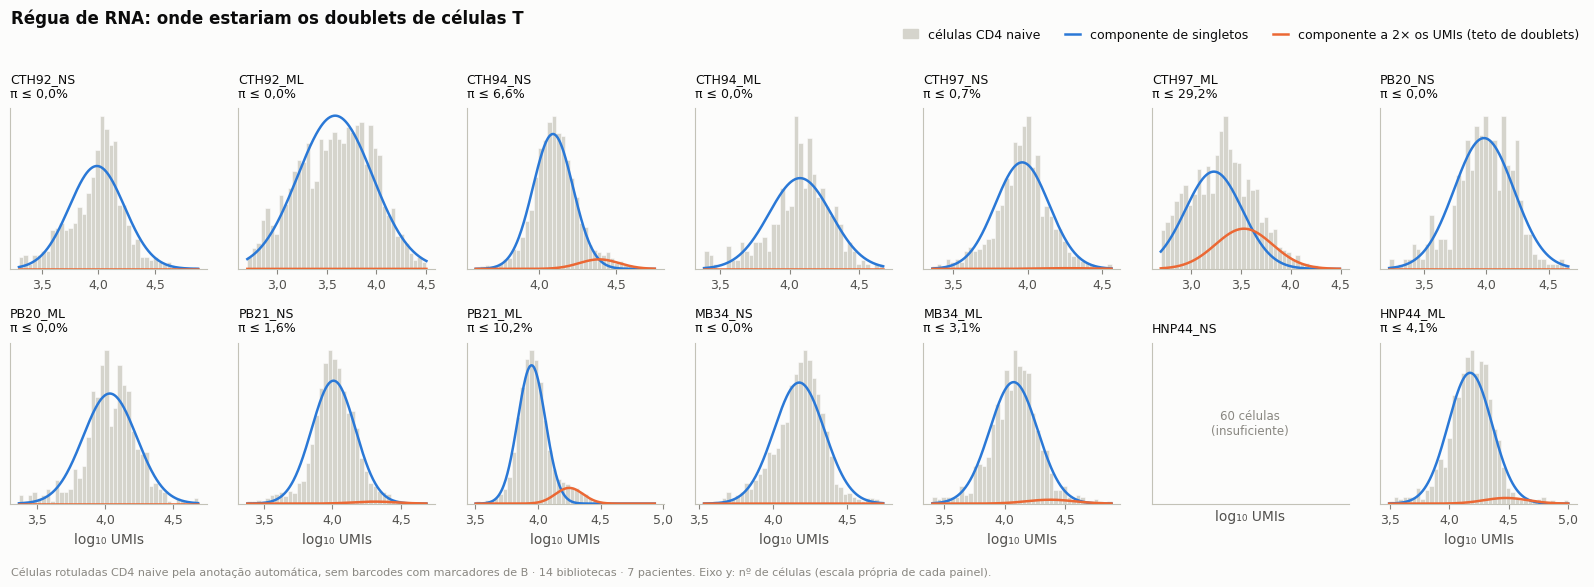

In [7]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5.6), sharey=False)
hist_rows = []
for ax, lib in zip(axes.ravel(), LIBS):
    q = pc[(pc["library_id"] == lib) & ~tem_b & (pc["azimuth_fino"] == "Naive CD4 T cell")]
    x = np.log10(q["umis"].to_numpy(dtype=float))
    if len(x) < 100 or lib not in naive.index or pd.isna(naive.loc[lib, "pi"]):
        ax.text(0.5, 0.5, f"{F.n(len(x))} células\n(insuficiente)", transform=ax.transAxes, ha="center",
                va="center", fontsize=8.5, color=INK["muted"])
        ax.set_title(lib, fontsize=9, fontweight="normal")
        ax.set_xticks([]); ax.set_yticks([])
        continue
    r = naive.loc[lib]
    bins = np.linspace(x.min(), x.max(), 41)
    ax.hist(x, bins=bins, color=plotting.CONTEXT, edgecolor=INK["surface"], linewidth=0.4, zorder=2)
    larg = bins[1] - bins[0]
    xs = np.linspace(x.min(), x.max(), 300)
    ax.plot(xs, len(x) * larg * (1 - r["pi"]) * db._norm_pdf(xs, r["mu"], r["dp_log10"]),
            color=plotting.CATEGORICAL[0], lw=1.8, zorder=3)
    ax.plot(xs, len(x) * larg * r["pi"] * db._norm_pdf(xs, r["mu"] + db.LOG10_2, r["dp_log10"]),
            color=plotting.CATEGORICAL[1], lw=1.8, zorder=4)
    ax.set_title(f"{lib}\nπ ≤ {F.pct(r['pi'])}", fontsize=9, fontweight="normal")
    ax.set_yticks([])
    ax.grid(False)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 1)))
    c, _ = np.histogram(x, bins=bins)
    hist_rows.append(pd.DataFrame({"library_id": lib, "log10_umis": (bins[:-1] + bins[1:]) / 2, "celulas": c}))
for ax in axes[-1]:
    ax.set_xlabel("log₁₀ UMIs")
handles = [mpl.patches.Patch(color=plotting.CONTEXT, label="células CD4 naive"),
           mpl.lines.Line2D([], [], color=plotting.CATEGORICAL[0], lw=1.8, label="componente de singletos"),
           mpl.lines.Line2D([], [], color=plotting.CATEGORICAL[1], lw=1.8, label="componente a 2× os UMIs (teto de doublets)")]
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(handles=handles, loc="upper right", ncol=3, bbox_to_anchor=(0.995, 0.965))
fig.suptitle("Régua de RNA: onde estariam os doublets de células T", x=0.01, y=0.985, ha="left",
             fontsize=12, fontweight="bold")
plotting.note(fig, f"Células rotuladas CD4 naive pela anotação automática, sem barcodes com marcadores de B · "
                   f"{plotting.N_DESIGN}. Eixo y: nº de células (escala própria de cada painel).")
plotting.savefig(fig, NB, "regua_de_rna", description="Distribuição de log-UMIs e componentes da mistura, por biblioteca",
                 data=pd.concat(hist_rows, ignore_index=True), data_index=False)
plt.show()

In [8]:
ok = naive.dropna(subset=["pi"])
rho_pi = stats.spearmanr(ok["pi"], ok["celulas"]).statistic
peq = ok[ok["celulas"] < 2000]
gra = ok[ok["celulas"] >= 2000]
largas = ok.index[ok["dp_log10"] > 0.25].tolist()
print(f"teto de doublets de células T (π), bibliotecas com menos de 2.000 células ({len(peq)}): "
      f"de {F.pct(peq['pi'].min())} a {F.pct(peq['pi'].max())}")
print("bibliotecas com 2.000 células ou mais: " + "; ".join(
    f"{l} π ≤ {F.pct(r['pi'])} (IC 95% {F.pct(r['pi_ic_inf'])}–{F.pct(r['pi_ic_sup'])}; esperado pelo 10x "
    f"{F.pct(r['taxa_esperada_10x'])})" for l, r in gra.iterrows()))
print(f"Spearman entre π e nº de células da biblioteca (n = {len(ok)}, descritivo): {F.f(rho_pi, 2)}")
print(f"distribuições largas (desvio-padrão de log₁₀ UMIs > 0,25), em que π é menos interpretável: {largas}")

teto de doublets de células T (π), bibliotecas com menos de 2.000 células (9): de 0,0% a 4,1%
bibliotecas com 2.000 células ou mais: CTH94_NS π ≤ 6,6% (IC 95% 5,5%–7,9%; esperado pelo 10x 4,5%); CTH97_ML π ≤ 29,2% (IC 95% 22,1%–33,4%; esperado pelo 10x 3,8%); PB21_NS π ≤ 1,6% (IC 95% 0,3%–3,4%; esperado pelo 10x 2,9%); PB21_ML π ≤ 10,2% (IC 95% 9,4%–11,1%; esperado pelo 10x 8,5%)
Spearman entre π e nº de células da biblioteca (n = 13, descritivo): 0,87
distribuições largas (desvio-padrão de log₁₀ UMIs > 0,25), em que π é menos interpretável: ['CTH92_ML', 'CTH97_ML']


**Leitura.** Nas bibliotecas pequenas — as de baixa recuperação — o
componente a 2× é praticamente vazio: a distribuição de UMIs é a de uma
única população. O teto só se afasta de zero nas bibliotecas com mais
células, e na ordem de grandeza da taxa que o 10x prevê para aquele
carregamento. É o comportamento do coencapsulamento ao acaso: mais células
carregadas, mais doublets. A hipótese em teste prevê o contrário — mais
doublets onde a recuperação foi pior — e não é o que se vê.

A exceção é CTH97_ML, com teto alto e distribuição muito larga. É a
biblioteca em que as células responderam ao estímulo (A02): células ativadas
têm conteúdo de RNA muito variável, e a régua não as separa de doublets.

In [9]:
vereditos.append({
    "linha": "régua de RNA",
    "resultado": f"teto de doublets T+T de {F.pct(peq['pi'].min())}–{F.pct(peq['pi'].max())} nas bibliotecas "
                 f"pequenas; correlação com o nº de células {F.f(rho_pi, 2)}",
    "o_que_prova": "não há excesso de doublets de células T nas bibliotecas de baixa recuperação",
    "o_que_nao_prova": "a taxa exata nas bibliotecas de distribuição larga (CTH97_ML)"})

## 3. Contaminantes como segunda espécie

Num experimento de mistura de espécies, a taxa de doublets é lida nos
barcodes que têm as duas. Aqui a "segunda espécie" são as poucas células B
que escaparam do sorting. Um barcode **com B** é o que tem ao menos 5 UMIs e
2 genes distintos entre marcadores de B que não são imunoglobulina. Ele
**também tem uma célula T** quando carrega ao menos um terço dos UMIs de
marcadores de T de uma célula T típica da mesma biblioteca, em 3 genes
distintos ou mais. A contaminação por RNA ambiente (≈ 1%, A02) fica duas
ordens de grandeza abaixo desse limiar.

In [10]:
t_ref = pc[(pc["azimuth_amplo"] == "T cell") & (pc["b"] == 0)].groupby("library_id")["t"].median()
pc["t_rel"] = pc["t"] / pc["library_id"].map(t_ref)
pc["com_B"] = tem_b
LIMIAR_T = 1 / 3
pc["duplo_TB"] = pc["com_B"] & (pc["t_rel"] >= LIMIAR_T) & (pc["t_n"] >= 3)
cb = pc[pc["com_B"]]
p_t = float((pc["azimuth_amplo"] == "T cell").mean())
p_b = float(len(cb) / len(pc))

sens = []
for lim in (0.2, LIMIAR_T, 0.5):
    k = int((cb["t_rel"] >= lim).sum() if lim != LIMIAR_T else cb["duplo_TB"].sum())
    lo, hi = db.wilson(k, len(cb))
    sens.append({"limiar_T_relativo": lim, "duplos": k, "com_B": len(cb), "r": k / len(cb),
                 "d": db.rate_from_contaminants(k / len(cb), p_t, p_b),
                 "d_ic_inf": db.rate_from_contaminants(lo, p_t, p_b),
                 "d_ic_sup": db.rate_from_contaminants(hi, p_t, p_b)})
sens = pd.DataFrame(sens).set_index("limiar_T_relativo")

soz = cb[cb["t_rel"] < 0.15]
dup = cb[cb["duplo_TB"]]
t_tip = pc[(pc["azimuth_amplo"] == "T cell") & (pc["b"] == 0)]
umis_cmp = pd.Series({"B sozinha": soz["umis"].median(), "célula T de referência": t_tip["umis"].median(),
                      "B + T": dup["umis"].median()})
print(f"barcodes com célula B: {F.n(len(cb))} ({F.pct(p_b, 2)} dos barcodes); também com célula T: "
      f"{F.n(len(dup))} ({F.pct(len(dup) / len(cb), 0)})")
print(f"UMIs medianos — B sozinha: {F.n(umis_cmp['B sozinha'])}; T de referência: "
      f"{F.n(umis_cmp['célula T de referência'])}; B + T: {F.n(umis_cmp['B + T'])} "
      f"(soma das duas primeiras: {F.n(umis_cmp['B sozinha'] + umis_cmp['célula T de referência'])})")
F.styler(sens, {"duplos": F.n, "com_B": F.n, "r": F.pct, "d": F.pct, "d_ic_inf": F.pct, "d_ic_sup": F.pct})

barcodes com célula B: 266 (0,76% dos barcodes); também com célula T: 70 (26%)
UMIs medianos — B sozinha: 11.968; T de referência: 9.372; B + T: 21.576 (soma das duas primeiras: 21.340)


,duplos,com_B,r,d,d_ic_inf,d_ic_sup
limiar_T_relativo,,,,,,
0.200000,101,266,"38,0%","24,1%","19,9%","28,9%"
0.333333,70,266,"26,3%","15,6%","12,4%","19,6%"
0.500000,66,266,"24,8%","14,6%","11,5%","18,4%"


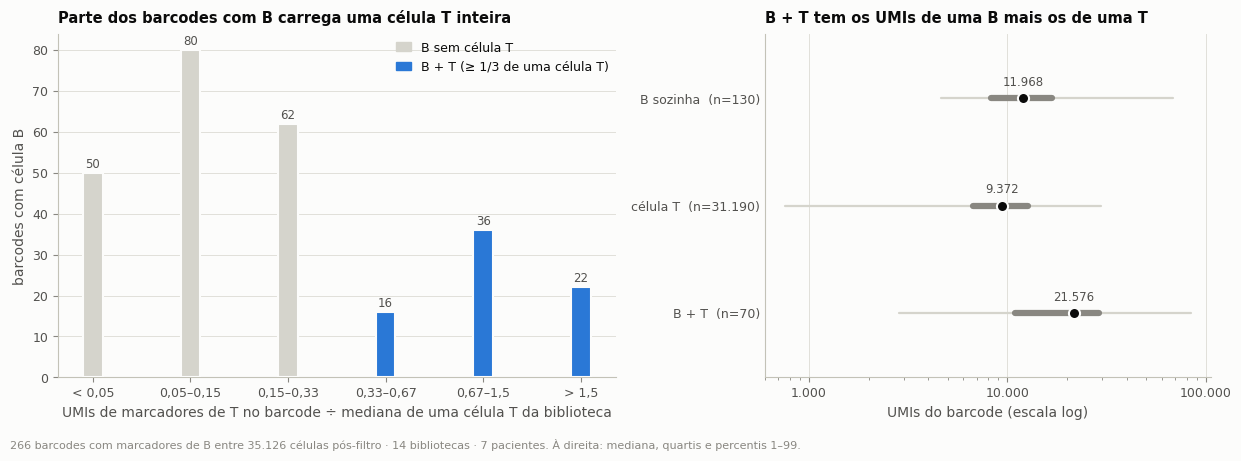

In [11]:
por_lib = cb.groupby("library_id").agg(com_B=("duplo_TB", "size"), duplos_TB=("duplo_TB", "sum")).reindex(LIBS).fillna(0).astype(int)
por_lib["celulas"] = n_lib
por_lib["frac_com_T"] = por_lib["duplos_TB"] / por_lib["com_B"].replace(0, np.nan)
por_lib["taxa_esperada_10x"] = arit["taxa_esperada_10x"]
por_lib["duplos_esperados_ao_acaso"] = [
    db.r_expected(d, p_t, nb / n if n else 0) * nb
    for d, nb, n in zip(por_lib["taxa_esperada_10x"], por_lib["com_B"], por_lib["celulas"])]
io.save_table(por_lib, NB, "contaminantes_por_biblioteca",
              description="Barcodes com célula B e fração que também tem célula T, por biblioteca")
obs_tot, esp_tot = int(por_lib["duplos_TB"].sum()), float(por_lib["duplos_esperados_ao_acaso"].sum())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
bins = [0, 0.05, 0.15, 1 / 3, 2 / 3, 1.5, max(2.0, cb["t_rel"].max() + 0.01)]
rot = ["< 0,05", "0,05–0,15", "0,15–0,33", "0,33–0,67", "0,67–1,5", "> 1,5"]
cont = pd.cut(cb["t_rel"], bins, labels=rot, right=False).value_counts().reindex(rot)
cores = [plotting.CONTEXT] * 3 + [plotting.ACCENT] * 3
xb = np.arange(len(rot))
ax.bar(xb, cont.to_numpy(), width=0.2, color=cores, edgecolor=INK["surface"], linewidth=1.5, zorder=3)
for xi, v in zip(xb, cont.to_numpy()):
    ax.annotate(F.n(v), (xi, v), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8.5,
                color=INK["secondary"])
ax.set_xticks(xb)
ax.set_xticklabels(rot)
ax.set_xlabel("UMIs de marcadores de T no barcode ÷ mediana de uma célula T da biblioteca")
ax.set_ylabel("barcodes com célula B")
ax.set_title("Parte dos barcodes com B carrega uma célula T inteira", fontsize=10.5)
handles = [mpl.patches.Patch(color=plotting.CONTEXT, label="B sem célula T"),
           mpl.patches.Patch(color=plotting.ACCENT, label="B + T (≥ 1/3 de uma célula T)")]
ax.legend(handles=handles, loc="upper right")
ax2 = axes[1]
grupos = [("B sozinha", soz["umis"]), ("célula T", t_tip["umis"]), ("B + T", dup["umis"])]
for yi, (nome, v) in zip([2, 1, 0], grupos):
    q01, q25, q50, q75, q99 = np.percentile(v, [1, 25, 50, 75, 99])
    ax2.plot([q01, q99], [yi, yi], color=plotting.CONTEXT, lw=1.6, zorder=1, solid_capstyle="round")
    ax2.plot([q25, q75], [yi, yi], color=INK["muted"], lw=4.5, zorder=2, solid_capstyle="round")
    ax2.plot(q50, yi, "o", ms=8, mfc=INK["primary"], mec=INK["surface"], mew=1.5, zorder=3)
    ax2.annotate(F.n(q50), (q50, yi), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5,
                 color=INK["secondary"])
ax2.set_yticks([2, 1, 0])
ax2.set_yticklabels([f"{g[0]}  (n={F.n(len(g[1]))})" for g in grupos])
ax2.set_ylim(-0.6, 2.6)
ax2.set_xscale("log")
ax2.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
ax2.set_xlabel("UMIs do barcode (escala log)")
ax2.grid(axis="x")
ax2.grid(axis="y", visible=False)
ax2.tick_params(axis="y", length=0)
ax2.set_title("B + T tem os UMIs de uma B mais os de uma T", fontsize=10.5)
fig.tight_layout()
plotting.note(fig, f"{F.n(len(cb))} barcodes com marcadores de B entre {F.n(len(pc))} células pós-filtro · "
                   f"{plotting.N_DESIGN}. À direita: mediana, quartis e percentis 1–99.")
plotting.savefig(fig, NB, "contaminantes", description="Barcodes com célula B: conteúdo de T e UMIs",
                 data=cont.rename("barcodes").to_frame())
plt.show()

In [12]:
peq_b = por_lib[(por_lib["celulas"] < 2000) & (por_lib["com_B"] >= 5)]
gra_b = por_lib[(por_lib["celulas"] >= 2000) & (por_lib["com_B"] >= 5)]
d_c, d_lo, d_hi = sens.loc[LIMIAR_T, ["d", "d_ic_inf", "d_ic_sup"]]
print(f"duplos T + B observados: {obs_tot}; esperados por coencapsulamento ao acaso na taxa do 10x: "
      f"{F.f(esp_tot, 0)} ({F.x(obs_tot / esp_tot, 1)})")
print(f"se a taxa valesse para todos os barcodes, d = {F.pct(d_c, 0)} (IC 95% {F.pct(d_lo, 0)}–{F.pct(d_hi, 0)})")
r_peq, r_gra = peq_b["duplos_TB"].sum() / peq_b["com_B"].sum(), gra_b["duplos_TB"].sum() / gra_b["com_B"].sum()
e_peq = peq_b["duplos_esperados_ao_acaso"].sum() / peq_b["com_B"].sum()
e_gra = gra_b["duplos_esperados_ao_acaso"].sum() / gra_b["com_B"].sum()
print(f"fração dos barcodes com B que têm T — bibliotecas com < 2.000 células: {F.pct(r_peq, 0)} "
      f"({peq_b['duplos_TB'].sum()}/{peq_b['com_B'].sum()}; esperado ao acaso {F.pct(e_peq, 0)}); "
      f"com ≥ 2.000: {F.pct(r_gra, 0)} ({gra_b['duplos_TB'].sum()}/{gra_b['com_B'].sum()}; esperado ao acaso "
      f"{F.pct(e_gra, 0)})")
print(f"esses duplos são {F.pct(obs_tot / len(pc), 2)} de todos os barcodes")
F.styler(por_lib, {"com_B": F.n, "duplos_TB": F.n, "celulas": F.n, "frac_com_T": lambda v: F.pct(v, 0),
                   "taxa_esperada_10x": F.pct, "duplos_esperados_ao_acaso": lambda v: F.f(v, 1)})

duplos T + B observados: 70; esperados por coencapsulamento ao acaso na taxa do 10x: 16 (4,4×)
se a taxa valesse para todos os barcodes, d = 16% (IC 95% 12%–20%)
fração dos barcodes com B que têm T — bibliotecas com < 2.000 células: 27% (35/130; esperado ao acaso 2%); com ≥ 2.000: 26% (35/134; esperado ao acaso 10%)
esses duplos são 0,20% de todos os barcodes


,com_B,duplos_TB,celulas,frac_com_T,taxa_esperada_10x,duplos_esperados_ao_acaso
library_id,,,,,,
CTH92_NS,1,0,812,0%,"0,6%","0,0"
CTH92_ML,5,3,1.538,60%,"1,2%","0,1"
CTH94_NS,74,18,5.579,24%,"4,5%","6,1"
CTH94_ML,9,7,500,78%,"0,4%","0,1"
CTH97_NS,11,4,1.517,36%,"1,2%","0,3"
CTH97_ML,9,6,4.696,67%,"3,8%","0,6"
PB20_NS,29,6,602,21%,"0,5%","0,3"
PB20_ML,28,4,781,14%,"0,6%","0,3"
PB21_NS,8,1,3.666,12%,"2,9%","0,4"


**Leitura.** Este é o único teste com validação interna, e ele encontra
doublets de verdade: os barcodes B + T têm o conteúdo de T de uma célula T
inteira e, em UMIs, a soma de uma célula B com uma célula T.

Eles são bem mais numerosos do que o coencapsulamento ao acaso prevê — e a
fração **não acompanha o carregamento**. Duas células caírem na mesma gota
por acaso é raro numa biblioteca pequena e mais comum numa grande; aqui, a
fração dos barcodes com B que carregam também uma T é praticamente a mesma
nos dois grupos. Uma fração constante, independente de quantas células
foram carregadas, é a assinatura de pares que já chegaram formados.

Há uma explicação direta para isso numa amostra enriquecida para CD4: uma
célula B grudada a uma T CD4⁺ é selecionada como CD4⁺. Boa parte das células
B "contaminantes" está ali porque veio presa a uma célula T — conjugado T–B,
um fenômeno conhecido de apresentação de antígeno.

Por isso a taxa lida nos contaminantes **não pode ser extrapolada** para as
células T em geral: ela mede a aderência T–B somada ao viés do sorting, não
a taxa com que duas células quaisquer dividem uma gota. Para os pares T + T
vale a régua da seção 2. Em número absoluto, os duplos T + B são uma fração
mínima dos barcodes.

In [13]:
log.add("MINOR", "conjugados T–B",
        "há doublets T + B validados, em número acima do coencapsulamento ao acaso",
        evidence=f"{obs_tot} barcodes com uma célula B e uma T contra {F.f(esp_tot, 0)} esperados ao acaso; "
                 f"UMIs medianos de {F.n(umis_cmp['B + T'])} ≈ B sozinha ({F.n(umis_cmp['B sozinha'])}) + T "
                 f"({F.n(umis_cmp['célula T de referência'])}); fração dos barcodes com B que têm T de "
                 f"{F.pct(r_peq, 0)} nas bibliotecas pequenas (esperado ao acaso {F.pct(e_peq, 0)}) e "
                 f"{F.pct(r_gra, 0)} nas grandes (esperado {F.pct(e_gra, 0)}) — não depende do carregamento",
        impact=f"são {F.pct(obs_tot / len(pc), 2)} dos barcodes: irrelevantes para a contagem de células, mas "
               "formam perfis mistos T + B que o Scrublet com threshold automático não remove",
        recommendation="remover barcodes com marcadores de B junto com os não-T na anotação; "
                       "não extrapolar essa taxa para pares T + T")
vereditos.append({
    "linha": "contaminantes como segunda espécie",
    "resultado": f"{obs_tot} doublets T + B validados ({F.x(obs_tot / esp_tot, 1)} o esperado ao acaso), "
                 f"{F.pct(obs_tot / len(pc), 2)} dos barcodes",
    "o_que_prova": "existem pares T–B pré-formados na suspensão (conjugados selecionados como CD4⁺)",
    "o_que_nao_prova": "a taxa de pares T + T: o viés do sorting impede a extrapolação"})

## 4. Scrublet

A01 mostrou que o threshold automático não chama quase ninguém. Com os
doublets T + B validados da seção 3 dá para medir o que o Scrublet enxerga,
com o threshold automático e com um threshold calibrado para marcar, em cada
biblioteca, a fração que a taxa do 10x prevê.

In [14]:
thr = pc.groupby("library_id").apply(
    lambda q: db.threshold_by_expected_rate(q["doublet_score"].to_numpy(), db.expected_doublet_rate_10x(len(q))))
pc["scrublet_calibrado"] = pc["doublet_score"] >= pc["library_id"].map(thr)
pc["score_percentil"] = pc.groupby("library_id")["doublet_score"].rank(pct=True)
scr = pd.DataFrame({
    "celulas": n_lib, "auto": pc.groupby("library_id")["scrublet_auto"].sum(),
    "calibrado": pc.groupby("library_id")["scrublet_calibrado"].sum(),
    "threshold_calibrado": thr, "duplos_TB": pc.groupby("library_id")["duplo_TB"].sum(),
    "duplos_TB_pegos_auto": pc[pc["duplo_TB"]].groupby("library_id")["scrublet_auto"].sum(),
    "duplos_TB_pegos_calibrado": pc[pc["duplo_TB"]].groupby("library_id")["scrublet_calibrado"].sum(),
}).reindex(LIBS).fillna(0)
io.save_table(scr, NB, "scrublet_auto_e_calibrado",
              description="Scrublet: chamadas com threshold automático e calibrado, e sensibilidade nos doublets T+B")
n_dup = int(pc["duplo_TB"].sum())
razao_umis = pc[pc["scrublet_calibrado"]]["umis"].median() / pc[~pc["scrublet_calibrado"]]["umis"].median()
print(f"threshold automático: {F.n(pc['scrublet_auto'].sum())} chamadas ({F.pct(pc['scrublet_auto'].mean(), 2)}); "
      f"calibrado: {F.n(pc['scrublet_calibrado'].sum())} ({F.pct(pc['scrublet_calibrado'].mean(), 1)})")
print(f"dos {n_dup} doublets T + B validados: {int(pc.loc[pc['duplo_TB'], 'scrublet_auto'].sum())} pegos pelo "
      f"automático, {int(pc.loc[pc['duplo_TB'], 'scrublet_calibrado'].sum())} pelo calibrado "
      f"({F.pct(pc.loc[pc['duplo_TB'], 'scrublet_calibrado'].mean(), 0)}); percentil mediano do score desses "
      f"doublets dentro da biblioteca: {F.pct(pc.loc[pc['duplo_TB'], 'score_percentil'].median(), 0)}")
print(f"células marcadas pelo calibrado têm {F.x(razao_umis)} os UMIs medianos das demais")

threshold automático: 62 chamadas (0,18%); calibrado: 1.807 (5,1%)
dos 70 doublets T + B validados: 1 pegos pelo automático, 19 pelo calibrado (27%); percentil mediano do score desses doublets dentro da biblioteca: 86%
células marcadas pelo calibrado têm 1,35× os UMIs medianos das demais


**Leitura.** O Scrublet dá aos doublets validados um score acima do típico,
mas não o bastante: o threshold automático perde praticamente todos, e o
calibrado pega só uma parte. A razão é estrutural — o método simula doublets
somando pares de células ao acaso, e numa população quase toda T os pares
simulados são T + T, indistinguíveis de uma célula T. O teste é pouco
sensível nesta amostra e não serve de evidência sobre a taxa de doublets, a
favor ou contra.

In [15]:
log.add("MAJOR", "Scrublet nesta população",
        "o Scrublet é pouco sensível mesmo para doublets validados",
        evidence=f"dos {n_dup} doublets T + B confirmados por marcadores e por UMIs, o threshold automático "
                 f"pega {int(pc.loc[pc['duplo_TB'], 'scrublet_auto'].sum())} e o calibrado "
                 f"{int(pc.loc[pc['duplo_TB'], 'scrublet_calibrado'].sum())}",
        impact="a etapa de remoção de doublets do pipeline original não cumpre o papel; perfis mistos "
               "permanecem no objeto",
        recommendation="marcar (sem remover) as células acima do threshold calibrado e os barcodes com "
                       "marcadores de B; usar como análise de sensibilidade ao interpretar clusters")
vereditos.append({
    "linha": "Scrublet",
    "resultado": f"{F.pct(pc['scrublet_auto'].mean(), 2)} chamadas com threshold automático; pega "
                 f"{int(pc.loc[pc['duplo_TB'], 'scrublet_auto'].sum())} de {n_dup} doublets validados",
    "o_que_prova": "nada sobre a taxa de doublets: o método não os enxerga nesta amostra",
    "o_que_nao_prova": "ausência de doublets"})

## 5. TRBC1/TRBC2 (exploratório)

Cada célula T usa TRBC1 **ou** TRBC2 na cadeia β produtiva. Se isso valesse
para o RNA, um barcode com as duas em proporção equilibrada indicaria duas
células T. O teste só é útil se a mistura for rara em singletos, e há um
controle para isso: os doublets T + B da seção 3 contêm **uma** célula T.

In [16]:
tt = pc[(pc["azimuth_amplo"] == "T cell") & ~pc["com_B"]].copy()
tt["trbc"] = tt["trbc1"] + tt["trbc2"]
tt = tt[tt["trbc"] >= 8]
tt["misto"] = (tt["trbc1"] / tt["trbc"]).between(0.25, 0.75)
tt["quartil_umis"] = tt.groupby("library_id")["umis"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=False))
tt["faixa_trbc"] = pd.cut(tt["trbc"], [7, 15, 30, np.inf], labels=["8–15", "16–30", "> 30"])
tabs = []
for _, g in tt.groupby(["library_id", "faixa_trbc"], observed=True):
    alto, baixo = g[g["quartil_umis"] == 3], g[g["quartil_umis"] == 0]
    if len(alto) >= 5 and len(baixo) >= 5:
        tabs.append(np.array([[alto["misto"].sum(), (~alto["misto"]).sum()],
                              [baixo["misto"].sum(), (~baixo["misto"]).sum()]]))
or_mh, or_lo, or_hi = db.mantel_haenszel_or(tabs)
ctrl = pc[pc["duplo_TB"]].copy()
ctrl["trbc"] = ctrl["trbc1"] + ctrl["trbc2"]
ctrl = ctrl[ctrl["trbc"] >= 8]
ctrl_misto = (ctrl["trbc1"] / ctrl["trbc"]).between(0.25, 0.75).mean()
trbc_tab = pd.DataFrame({"n": [len(tt), len(ctrl)], "frac_mista": [tt["misto"].mean(), ctrl_misto]},
                        index=["células T (≥ 8 UMIs de TRBC)", "controle: doublets T + B (uma célula T)"])
io.save_table(trbc_tab, NB, "trbc_misto", description="Fração de barcodes com TRBC1 e TRBC2 em proporção equilibrada")
print(f"células T com ≥ 8 UMIs de TRBC: {F.n(len(tt))}; com TRBC1 e TRBC2 em proporção 25–75%: "
      f"{F.pct(tt['misto'].mean(), 0)}")
print(f"controle com uma única célula T (doublets T + B, n = {len(ctrl)}): {F.pct(ctrl_misto, 0)}")
print(f"razão de chances de 'misto', quartil superior × inferior de UMIs, estratificada por biblioteca e por "
      f"contagem de TRBC (Mantel–Haenszel): {F.f(or_mh, 2)} (IC 95% {F.f(or_lo, 2)}–{F.f(or_hi, 2)})")

células T com ≥ 8 UMIs de TRBC: 19.709; com TRBC1 e TRBC2 em proporção 25–75%: 34%
controle com uma única célula T (doublets T + B, n = 59): 53%
razão de chances de 'misto', quartil superior × inferior de UMIs, estratificada por biblioteca e por contagem de TRBC (Mantel–Haenszel): 1,25 (IC 95% 1,14–1,37)


**Leitura.** O teste não é informativo. Cerca de um terço das células T tem
as duas formas em proporção equilibrada, e o controle com uma única célula T
por barcode tem ainda mais. A exclusão TRBC1/TRBC2 vale para a proteína; no
RNA há transcrito do alelo não produtivo, e a "mistura" acompanha o conteúdo
do barcode, não o número de células T. Fica registrado para que não seja
tentado de novo como prova.

In [17]:
vereditos.append({
    "linha": "TRBC1/TRBC2",
    "resultado": f"{F.pct(tt['misto'].mean(), 0)} das células T são 'mistas'; controle com uma célula T: "
                 f"{F.pct(ctrl_misto, 0)}",
    "o_que_prova": "nada: a exclusão mútua não vale no nível de RNA",
    "o_que_nao_prova": "—"})

## 6. Então por que poucas células?

Os dados de sequenciamento não dizem quantas células foram carregadas. Mas
dizem algo sobre o estado da suspensão, pelo que ficou fora das células.

In [18]:
nuc = io.load_data("A02_preprocessamento_adicional", "barcodes_tipo_nucleo").set_index("library_id")
amb = pd.read_csv(config.TABLES / "A02_preprocessamento_adicional" / "rna_ambiente.csv", index_col=0)
mol = io.load_data("C03_rarefacao_citocinas", "mol_resumo").set_index("library_id")
sint = pd.DataFrame({
    "celulas": n_lib, "taxa_esperada_10x": arit["taxa_esperada_10x"], "teto_doublets_TT": naive["pi"],
    "barcodes_tipo_nucleo": nuc["tipo_nucleo"], "tipo_nucleo_por_celula": nuc["tipo_nucleo_por_celula"],
    "umis_fora_de_celulas": amb["umis_fora_de_celulas"],
    # RNA fora de células expresso em "células": UMIs fora ÷ UMIs medianos de uma célula
    "rna_livre_em_equivalentes_de_celula": (mol["moleculas"] - mol["moleculas_em_celulas"]) / mol["umis_medianos"],
}).reindex(LIBS)
sint["equivalentes_por_celula"] = sint["rna_livre_em_equivalentes_de_celula"] / mol["celulas"]
io.save_table(sint, NB, "recuperacao_sintese", description="Recuperação de células: síntese por biblioteca")
com_nuc = sint.index[sint["tipo_nucleo_por_celula"] >= 0.5].tolist()
menores = sint.sort_values("celulas").head(6)
print(f"bibliotecas com material nuclear de células mortas em quantidade comparável à de células: {com_nuc}")
print("  " + "; ".join(f"{l}: {F.n(sint.loc[l, 'barcodes_tipo_nucleo'])} barcodes para "
                       f"{F.n(sint.loc[l, 'celulas'])} células" for l in com_nuc))
print(f"nas 6 bibliotecas com menos células ({', '.join(menores.index)}): no máximo "
      f"{F.n(menores['barcodes_tipo_nucleo'].max())} desses barcodes; UMIs fora de células de "
      f"{F.pct(menores['umis_fora_de_celulas'].min(), 0)} a {F.pct(menores['umis_fora_de_celulas'].max(), 0)}")
print(f"  RNA fora de células nessas 6, em equivalentes de célula: de "
      f"{F.n(menores['rna_livre_em_equivalentes_de_celula'].min())} a "
      f"{F.n(menores['rna_livre_em_equivalentes_de_celula'].max())} — de "
      f"{F.f(menores['equivalentes_por_celula'].min(), 1)} a {F.f(menores['equivalentes_por_celula'].max(), 1)} "
      "por célula capturada")
print(f"  células + equivalentes livres nessas 6: de "
      f"{F.n((menores['celulas'] + menores['rna_livre_em_equivalentes_de_celula']).min())} a "
      f"{F.n((menores['celulas'] + menores['rna_livre_em_equivalentes_de_celula']).max())}")
F.styler(sint, {"celulas": F.n, "taxa_esperada_10x": F.pct, "teto_doublets_TT": F.pct,
                "barcodes_tipo_nucleo": F.n, "tipo_nucleo_por_celula": lambda v: F.f(v, 2),
                "umis_fora_de_celulas": lambda v: F.pct(v, 0),
                "rna_livre_em_equivalentes_de_celula": F.n, "equivalentes_por_celula": lambda v: F.f(v, 1)})

bibliotecas com material nuclear de células mortas em quantidade comparável à de células: ['CTH97_NS', 'PB21_NS', 'MB34_NS']
  CTH97_NS: 4.873 barcodes para 1.517 células; PB21_NS: 21.097 barcodes para 3.666 células; MB34_NS: 1.289 barcodes para 1.924 células
nas 6 bibliotecas com menos células (HNP44_NS, CTH94_ML, PB20_NS, PB20_ML, CTH92_NS, MB34_ML): no máximo 34 desses barcodes; UMIs fora de células de 28% a 53%
  RNA fora de células nessas 6, em equivalentes de célula: de 128 a 778 — de 0,4 a 1,1 por célula capturada
  células + equivalentes livres nessas 6: de 216 a 1.590


,celulas,taxa_esperada_10x,teto_doublets_TT,barcodes_tipo_nucleo,tipo_nucleo_por_celula,umis_fora_de_celulas,rna_livre_em_equivalentes_de_celula,equivalentes_por_celula
library_id,,,,,,,,
CTH92_NS,812,"0,6%","0,0%",7,"0,01",46%,778,"0,9"
CTH92_ML,1.538,"1,2%","0,0%",3,"0,00",43%,1.624,"1,0"
CTH94_NS,5.579,"4,5%","6,6%",46,"0,01",12%,893,"0,1"
CTH94_ML,500,"0,4%","0,0%",0,"0,00",44%,467,"0,9"
CTH97_NS,1.517,"1,2%","0,7%",4.873,"2,99",28%,662,"0,4"
CTH97_ML,4.696,"3,8%","29,2%",5,"0,00",15%,1.208,"0,3"
PB20_NS,602,"0,5%","0,0%",8,"0,01",35%,381,"0,6"
PB20_ML,781,"0,6%","0,0%",8,"0,01",28%,359,"0,4"
PB21_NS,3.666,"2,9%","1,6%",21.097,"4,95",22%,1.201,"0,3"


**Leitura.** Há dois padrões diferentes, e nenhum é o de doublets.

* Em três bibliotecas não estimuladas (A02) a suspensão tinha muito material
  nuclear de células mortas — em duas delas, várias vezes mais barcodes
  desse tipo do que células. Ali houve morte celular extensa antes da
  captura.
* Nas bibliotecas com **menos** células esse material quase não existe. O
  que há é RNA livre: os UMIs fora de células equivalem, em ordem de
  grandeza, ao conteúdo de tantas células quantas foram capturadas — sinal de
  que parte das células se rompeu. Mas mesmo somando esse RNA livre às
  células capturadas, o total fica em centenas a poucos milhares de
  células-equivalentes. Não há sinal de milhares de células que entraram no
  chip e se perderam: o mais provável é que poucas células tenham chegado ao
  carregamento — perda a montante, no sorting, na cultura ou na contagem.
  (A conta supõe que o RNA livre seja capturado como o de uma célula e não
  tenha degradado; é uma ordem de grandeza, não uma medida.)

Em ambos os casos a informação que fecha a questão está no registro de
bancada: células contadas e viabilidade antes do carregamento.

In [19]:
log.add("MAJOR", "hipótese: baixa recuperação por excesso de doublets",
        "os dados não sustentam a hipótese de que doublets expliquem a baixa recuperação",
        evidence=f"teto de doublets T + T de {F.pct(peq['pi'].min())}–{F.pct(peq['pi'].max())} nas bibliotecas "
                 f"com menos de 2.000 células, e correlação de {F.f(rho_pi, 2)} entre esse teto e o nº de "
                 f"células (o esperado do carregamento, o oposto da hipótese); taxa esperada de multipletos "
                 f"≤ {F.pct(poucas['taxa_esperada_10x'].max())} nessas bibliotecas; os únicos doublets em "
                 f"excesso são pares T–B ({F.pct(obs_tot / len(pc), 2)} dos barcodes)",
        impact="procurar e remover doublets não vai recuperar células; a causa está antes da captura",
        recommendation="conferir no registro de bancada o nº de células carregadas e a viabilidade por "
                       "amostra; em novas capturas, contar e medir viabilidade imediatamente antes de "
                       "carregar, e considerar multiplexar amostras (hashing), que dá a taxa de doublets "
                       "diretamente")
vereditos.append({
    "linha": "o que ficou fora das células",
    "resultado": f"material nuclear de células mortas abundante em {', '.join(com_nuc)}; quase ausente nas "
                 "bibliotecas com menos células",
    "o_que_prova": "morte celular antes da captura em três bibliotecas; nas menores, falta de células na entrada",
    "o_que_nao_prova": "quantas células foram carregadas"})

## Síntese

In [20]:
flags = pc[["library_id", "barcode", "com_B", "duplo_TB", "t_rel", "scrublet_auto", "scrublet_calibrado",
            "score_percentil"]].copy()
io.save_data(flags, NB, "flags_doublets", description="Flags de doublet por célula pós-filtro MAD")
ver = pd.DataFrame(vereditos).set_index("linha")
io.save_table(ver, NB, "vereditos", description="Hipótese de doublets: o que cada linha de evidência mostra")
show(ver.reset_index())

linha,resultado,o_que_prova,o_que_nao_prova
aritmética do carregamento,"taxa esperada ≤ 1,5% nas bibliotecas pequenas; doublets reduzem a contagem em no máximo 2×","doublets não podem, sozinhos, explicar déficits de mais de 2×",se há ou não excesso de doublets
régua de RNA,"teto de doublets T+T de 0,0%–4,1% nas bibliotecas pequenas; correlação com o nº de células 0,87",não há excesso de doublets de células T nas bibliotecas de baixa recuperação,a taxa exata nas bibliotecas de distribuição larga (CTH97_ML)
contaminantes como segunda espécie,"70 doublets T + B validados (4,4× o esperado ao acaso), 0,20% dos barcodes",existem pares T–B pré-formados na suspensão (conjugados selecionados como CD4⁺),a taxa de pares T + T: o viés do sorting impede a extrapolação
Scrublet,"0,18% chamadas com threshold automático; pega 1 de 70 doublets validados",nada sobre a taxa de doublets: o método não os enxerga nesta amostra,ausência de doublets
TRBC1/TRBC2,34% das células T são 'mistas'; controle com uma célula T: 53%,nada: a exclusão mútua não vale no nível de RNA,—
o que ficou fora das células,"material nuclear de células mortas abundante em CTH97_NS, PB21_NS, MB34_NS; quase ausente nas bibliotecas com menos células","morte celular antes da captura em três bibliotecas; nas menores, falta de células na entrada",quantas células foram carregadas


In [21]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       2
MINOR       1
INFO        0


severity,location,problem,evidence,impact,recommendation
MAJOR,Scrublet nesta população,o Scrublet é pouco sensível mesmo para doublets validados,"dos 70 doublets T + B confirmados por marcadores e por UMIs, o threshold automático pega 1 e o calibrado 19",a etapa de remoção de doublets do pipeline original não cumpre o papel; perfis mistos permanecem no objeto,marcar (sem remover) as células acima do threshold calibrado e os barcodes com marcadores de B; usar como análise de sensibilidade ao interpretar clusters
MAJOR,hipótese: baixa recuperação por excesso de doublets,os dados não sustentam a hipótese de que doublets expliquem a baixa recuperação,"teto de doublets T + T de 0,0%–4,1% nas bibliotecas com menos de 2.000 células, e correlação de 0,87 entre esse teto e o nº de células (o esperado do carregamento, o oposto da hipótese); taxa esperada de multipletos ≤ 1,5% nessas bibliotecas; os únicos doublets em excesso são pares T–B (0,20% dos barcodes)",procurar e remover doublets não vai recuperar células; a causa está antes da captura,"conferir no registro de bancada o nº de células carregadas e a viabilidade por amostra; em novas capturas, contar e medir viabilidade imediatamente antes de carregar, e considerar multiplexar amostras (hashing), que dá a taxa de doublets diretamente"
MINOR,conjugados T–B,"há doublets T + B validados, em número acima do coencapsulamento ao acaso",70 barcodes com uma célula B e uma T contra 16 esperados ao acaso; UMIs medianos de 21.576 ≈ B sozinha (11.968) + T (9.372); fração dos barcodes com B que têm T de 27% nas bibliotecas pequenas (esperado ao acaso 2%) e 26% nas grandes (esperado 10%) — não depende do carregamento,"são 0,20% dos barcodes: irrelevantes para a contagem de células, mas formam perfis mistos T + B que o Scrublet com threshold automático não remove",remover barcodes com marcadores de B junto com os não-T na anotação; não extrapolar essa taxa para pares T + T


## Conclusão

A hipótese não se sustenta. Nas bibliotecas de baixa recuperação a
distribuição de RNA por barcode é a de células únicas; onde aparece um
componente compatível com doublets, ele está nas bibliotecas com **mais**
células e na proporção que o carregamento prevê. E a aritmética limita o
efeito de qualquer taxa plausível de doublets a uma fração da diferença.

Doublets existem, e um tipo deles está em excesso: pares T–B, validados
pelos marcadores e pelos UMIs, que chegam formados porque uma célula B presa
a uma T CD4⁺ passa pelo enriquecimento. São poucos, não afetam a contagem,
e o Scrublet não os remove.

O que os dados mostram sobre a recuperação aponta para antes da captura:
células mortas em algumas amostras, poucas células na entrada em outras.
Uma prova direta da taxa de doublets exigiria amostras multiplexadas
(hashing ou mistura de doadores) numa captura futura.

In [22]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

13 artefatos gravados por este notebook:
                        name    kind
  aritmetica_do_carregamento   table
                regua_de_rna   table
            fig_regua_de_rna  figure
            fig_regua_de_rna   table
contaminantes_por_biblioteca   table
           fig_contaminantes  figure
           fig_contaminantes   table
   scrublet_auto_e_calibrado   table
                  trbc_misto   table
         recuperacao_sintese   table
              flags_doublets parquet
                   vereditos   table
                      issues   table
